Dataset: Shell Commands Used by Participants of Hands-on Cybersecurity Training
(https://zenodo.org/records/6670113)

In [1]:
import requests, zipfile, io, os
from st_router.paths import get_rootdir
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
ROOT_DIR = get_rootdir()
DATA_RAW = ROOT_DIR / "data" / "raw"
DATA_PROC = ROOT_DIR / "data" / "processed"
MASARYK_DIR = DATA_RAW / "masaryk"

In [2]:
r = requests.get("https://zenodo.org/records/6670113/files/data.zip?download=1")
z = zipfile.ZipFile(io.BytesIO(r.content))
z.extractall(MASARYK_DIR)

# go to README.md and verify version 21762

In [3]:
for training in MASARYK_DIR.iterdir():
    count = 0
    for _ in training.rglob("*.json"):
        count += 1
    print(training.name + ":", count)

README.md: 0
House of cards: 22
Secret laboratory: 13
Webmin exploit practice: 10
SQL injection: 8
Junior hacker: 18
Locust 3302: 134
Junior hacker adaptive: 62


In [4]:
dfs = []

for file in MASARYK_DIR.rglob("*.json"):
    path_parts = file.relative_to(MASARYK_DIR).parts
    training = path_parts[0]
    # only add run if path resolves to 3 or more dirs e.g. house of cards/2019... [0][1] and [2] is json
    if (len(path_parts) >= 3):
        run = path_parts[1]
    else:
        run = None
    df = pd.read_json(file, lines=True)
    df["training"] = training
    df["full_path"] = str(file.relative_to(MASARYK_DIR))
    df["run"] = run
    dfs.append(df)

long_df = pd.concat(dfs, ignore_index=True)

long_df.head()

,hostname,ip,timestamp_str,sandbox_id,cmd,pool_id,wd,cmd_type,username,training,full_path,run,tags
0,attacker,10.1.135.83,2021-07-08 15:41:13.409000+00:00,130,nmap,30,/home/kali,bash-command,kali,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN
1,attacker,10.1.135.83,2021-07-08 15:41:13.409000+00:00,130,metasploit,30,/home/kali,bash-command,kali,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN
2,attacker,10.1.135.83,2021-07-08 15:41:41.937000+00:00,130,msf,30,/home/kali,bash-command,kali,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN
3,attacker,10.1.135.83,2021-07-08 15:42:47.127000+00:00,130,help,30,NaN,msf-command,NaN,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN
4,attacker,10.1.135.83,2021-07-08 15:48:40.157000+00:00,130,nmap 10.1.26.9,30,/home/kali,bash-command,kali,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN


In [5]:
# check how many run folders
s = long_df.groupby("training")["run"].nunique()
print(s[s>1])
print()
# check if pool_id can stand in for run
s = long_df.groupby(["training", "run"])["pool_id"].nunique()
print(s[s>1])
print()
# does each pool belong to exactly one run
s = long_df.groupby(["training", "pool_id"])["run"].nunique()
print(s[s>1])
print()

# check if training, pool id, sandbox id can form unique key for user
s = long_df.groupby(["training", "pool_id", "sandbox_id"])["run"].nunique()
print(s)
print()
# they do

# check if only one sandbox id per file
s = long_df.groupby("full_path")["sandbox_id"].nunique()
print(s)
print()
print((s > 1).sum())


training
House of cards            3
Junior hacker adaptive    8
Locust 3302               9
Name: run, dtype: int64

training     run       
Locust 3302  2022-05-04    4
Name: pool_id, dtype: int64

training        pool_id
House of cards  0          3
Locust 3302     1          3
Name: run, dtype: int64

training                 pool_id  sandbox_id
House of cards           0        93            1
                                  95            1
                                  101           1
                                  112           1
                                  113           1
                                               ..
Webmin exploit practice  1        329           0
                                  331           0
                                  351           0
                                  358           0
                                  374           0
Name: run, Length: 267, dtype: int64

full_path
House of cards/2019-08-15 KYPO Summer School/sandb

We can use training, pool id and sandbox id as a unique key for each user.

In [6]:
# joining three unique key columns as string 
long_df["unique_key"] = long_df["training"] + "_" + long_df["pool_id"].astype(str) + "_" + long_df["sandbox_id"].astype(str)

long_df.head()

,hostname,ip,timestamp_str,sandbox_id,cmd,pool_id,wd,cmd_type,username,training,full_path,run,tags,unique_key
0,attacker,10.1.135.83,2021-07-08 15:41:13.409000+00:00,130,nmap,30,/home/kali,bash-command,kali,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN,Secret laboratory_30_130
1,attacker,10.1.135.83,2021-07-08 15:41:13.409000+00:00,130,metasploit,30,/home/kali,bash-command,kali,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN,Secret laboratory_30_130
2,attacker,10.1.135.83,2021-07-08 15:41:41.937000+00:00,130,msf,30,/home/kali,bash-command,kali,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN,Secret laboratory_30_130
3,attacker,10.1.135.83,2021-07-08 15:42:47.127000+00:00,130,help,30,NaN,msf-command,NaN,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN,Secret laboratory_30_130
4,attacker,10.1.135.83,2021-07-08 15:48:40.157000+00:00,130,nmap 10.1.26.9,30,/home/kali,bash-command,kali,Secret laboratory,Secret laboratory/sandbox-130-useractions.json,None,NaN,Secret laboratory_30_130


We now need to gather the 10 consecutive commands of each user in a rolling window. The window of 10 was chosen to reflect the context rules of smart terminal

In [7]:
long_df["timestamp"] = pd.to_datetime(long_df["timestamp_str"], utc=True)
long_df = long_df.drop(columns = "timestamp_str")

long_df = long_df.sort_values(["unique_key", "timestamp"], kind="mergesort")

In [8]:
# TODO: make util helper for col rearranging
first = ["unique_key", "timestamp"]
col_list = first + [c for c in long_df.columns if c not in first]
long_df = long_df[col_list]
long_df.head()

,unique_key,timestamp,hostname,ip,sandbox_id,cmd,pool_id,wd,cmd_type,username,training,full_path,run,tags
21063,House of cards_0_101,2019-09-26 09:23:29.156399+00:00,attacker,10.0.135.83,101,nmap -sV,0,/root,bash-command,root,House of cards,House of cards/2019-09-19 PV276 First Lesson/s...,2019-09-19 PV276 First Lesson,NaN
21064,House of cards_0_101,2019-09-26 09:23:53.451916+00:00,attacker,10.0.135.83,101,nmap --help,0,/root,bash-command,root,House of cards,House of cards/2019-09-19 PV276 First Lesson/s...,2019-09-19 PV276 First Lesson,NaN
21065,House of cards_0_101,2019-09-26 09:24:40.283127+00:00,attacker,10.0.135.83,101,nmap -sV 172.18.1.5,0,/root,bash-command,root,House of cards,House of cards/2019-09-19 PV276 First Lesson/s...,2019-09-19 PV276 First Lesson,NaN
21066,House of cards_0_101,2019-09-26 09:31:56.239241+00:00,attacker,10.0.135.83,101,nmap --help,0,/root,bash-command,root,House of cards,House of cards/2019-09-19 PV276 First Lesson/s...,2019-09-19 PV276 First Lesson,NaN
21067,House of cards_0_101,2019-09-26 09:36:58.199192+00:00,attacker,10.0.135.83,101,search libssh,0,NaN,msf-command,NaN,House of cards,House of cards/2019-09-19 PV276 First Lesson/s...,2019-09-19 PV276 First Lesson,NaN


In [9]:
# all cols with non-empty tags are the only ones with empty cmds -- drop
print(long_df["tags"].notnull().sum())
print(long_df["cmd"].isna().sum())

long_df = long_df.dropna(subset=["cmd"])

# dropping useless cols
long_df = long_df.drop(columns=["username", "ip", "full_path", "pool_id", "sandbox_id", "run", "tags"])

19
19


Need to decide when a session ends. Can group by timestamp differences and decide on threshold between consecutive commands which constitutes a session break.

In [10]:
long_df = long_df.reset_index(drop=True)
long_df["gap_s"] = long_df.groupby("unique_key")["timestamp"].diff().dt.total_seconds()

In [11]:
display(long_df.describe())
display(long_df["gap_s"].quantile([0.9, 0.95, 0.99, 0.999]))

,gap_s
count,21125.000000
mean,294.363824
std,8909.016306
min,0.000000
25%,3.599097
50%,12.867000
75%,46.711000
max,721217.754000


0.900      132.821800
0.950      239.513600
0.990      872.701120
0.999    36101.033815
Name: gap_s, dtype: float64

15 minutes< | count: 203
30 minutes< | count: 69
60 minutes< | count: 38
120 minutes< | count: 28
360 minutes< | count: 23
720 minutes< | count: 20


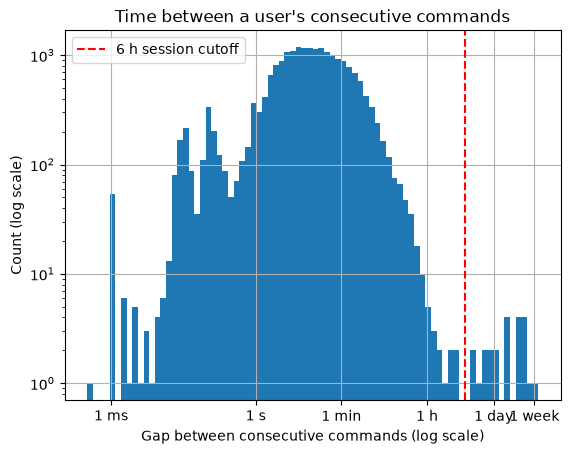

In [12]:
mins = [15, 30, 60, 120, 360, 720]

for m in mins:
    s = m * 60
    print(f"{m} minutes< | count: {(long_df['gap_s'] > s).sum()}")

gap_series = long_df.loc[long_df["gap_s"] > 0, "gap_s"]
lgap_series = np.log10(gap_series)

lgap_series.hist(bins=80)
plt.yscale("log")

tick_seconds = [0.001, 1, 60, 3600, 86400, 604800]
tick_labels = ["1 ms", "1 s", "1 min", "1 h", "1 day", "1 week"]
plt.xticks(np.log10(tick_seconds), tick_labels)

plt.axvline(np.log10(6 * 3600), color="red", linestyle="--", label="6 h session cutoff")
plt.legend()

plt.xlabel("Gap between consecutive commands (log scale)")
plt.ylabel("Count (log scale)")
plt.title("Time between a user's consecutive commands")
plt.show()

We pick 6 hours as cutoff as it falls in the empty stretch between the high density (~3.5hr) region and the overnight 9hr< group

In [13]:
CUTOFF = 6 * 3600

long_df["session_exceed"] = long_df["gap_s"] > CUTOFF
long_df["session"] = long_df.groupby("unique_key")["session_exceed"].cumsum()
long_df["session"].value_counts()

session
0    20552
1      799
2       41
Name: count, dtype: int64

Smart terminal only runs on zsh so metasploit commands should be dropped. need to assess how this will affect training set

In [14]:
long_df.groupby("training")["cmd_type"].value_counts(normalize=True)
bash_df = long_df[long_df["cmd_type"] == "bash-command"].copy()
print(bash_df.groupby("unique_key").size().describe())
print()
print(bash_df.groupby(["unique_key", "session"]).ngroups)

count    267.000000
mean      61.303371
std       51.484227
min        4.000000
25%       22.000000
50%       50.000000
75%       78.500000
max      323.000000
dtype: float64

290


Dropping the metasploit rows doesn't remove any users entirely (minimum commands is 4) and all 290 sessions are kept i.e. no sessions were only metasploit.

In [15]:
bash_df = bash_df.copy()
k = 10

g = bash_df.groupby(["unique_key", "session"])["cmd"]
for i in range(1, k + 1):
    bash_df[f"prev_{i}"] = g.shift(i)

# count non-empty prev rows per window
prev_cols = [f"prev_{i}" for i in range(1, k + 1)]

bash_df["window_len"] = bash_df[prev_cols].notna().sum(axis=1)
bash_df["window_len"].value_counts().sort_index()

window_len
0       290
1       287
2       281
3       281
4       278
5       275
6       272
7       269
8       266
9       261
10    13608
Name: count, dtype: int64

In [16]:
cols = ["unique_key", "session", "cmd", "prev_1", "prev_2", "window_len"]

# first 3 rows of each session
first_rows = bash_df.groupby(["unique_key", "session"]).head(3)

display(first_rows[cols].head(6))                            
display(first_rows.loc[first_rows["session"] == 1, cols].head(6))

,unique_key,session,cmd,prev_1,prev_2,window_len
0,House of cards_0_101,0,nmap -sV,NaN,NaN,0
1,House of cards_0_101,0,nmap --help,nmap -sV,NaN,1
2,House of cards_0_101,0,nmap -sV 172.18.1.5,nmap --help,nmap -sV,2
20,House of cards_0_112,0,nmap -sP 192.168.0.0-100,NaN,NaN,0
21,House of cards_0_112,0,ifconfig,nmap -sP 192.168.0.0-100,NaN,1
22,House of cards_0_112,0,nmap --help,ifconfig,nmap -sP 192.168.0.0-100,2


,unique_key,session,cmd,prev_1,prev_2,window_len
67,House of cards_0_112,1,ssh 172.18.1.5,NaN,NaN,0
68,House of cards_0_112,1,ssh 172.18.1.5 -l alice,ssh 172.18.1.5,NaN,1
69,House of cards_0_112,1,ssh 172.18.1.5 -l alice,ssh 172.18.1.5 -l alice,ssh 172.18.1.5,2
124,House of cards_0_115,1,ssh 172.18.1.5,NaN,NaN,0
125,House of cards_0_115,1,ssh alice@172.18.1.5,ssh 172.18.1.5,NaN,1
161,House of cards_0_116,1,ssh alice@172.18.1.5,NaN,NaN,0


Commands one after the other in less than a second contaminate data as they are likely coming from a copy paste, or through a tool

In [17]:
ssmask = bash_df['gap_s'] < 1
ssrows = (ssmask).sum()
print(ssrows, "subsecond cols ", (ssrows/bash_df.shape[0])*100, "% of bash df")
display(bash_df[bash_df['gap_s'] < 1].head())

# check how many are duplicates
dups_mask = ssmask & (bash_df["cmd"] == bash_df["prev_1"])
dups = (dups_mask).sum()
print(dups, "duplicates", (dups/ssrows)*100, "% of ss rows")

print(bash_df.loc[dups_mask, "gap_s"].describe())

same = bash_df["cmd"] == bash_df["prev_1"]

# normal speed vs sub-second
print(same[bash_df["gap_s"] >= 1].mean(), same[ssmask].mean())

# timing of non-duplicate sub-second rows
display(bash_df.loc[ssmask & ~same, "gap_s"].describe())

# Examples
display(bash_df.loc[ssmask & ~same, ["gap_s", "prev_1", "cmd"]].head(15))

1940 subsecond cols  11.852394916911047 % of bash df


,unique_key,timestamp,hostname,cmd,wd,cmd_type,training,gap_s,session_exceed,session,...,prev_2,prev_3,prev_4,prev_5,prev_6,prev_7,prev_8,prev_9,prev_10,window_len
593,House of cards_0_396,2019-08-14 16:06:01.993822+00:00,attacker,ss -lntp | grep post,/root,bash-command,House of cards,0.035795,False,0,...,clear,service postgresql start,service postgresql stop,service postgresql status,service postgresql,service postgresql reload,service postgresql,service postgresql status,service postgresql restart,10
595,House of cards_0_396,2019-08-14 16:06:04.440162+00:00,attacker,ss -lntp | grep post,/root,bash-command,House of cards,0.022193,False,0,...,ss -lntp | grep post,ss -lntp | grep post,clear,service postgresql start,service postgresql stop,service postgresql status,service postgresql,service postgresql reload,service postgresql,10
600,House of cards_0_396,2019-08-14 16:06:56.033314+00:00,attacker,ss -lntp | grep post,/root,bash-command,House of cards,0.015344,False,0,...,service postgresql status,systemctl restart postgresql,systemctl daemon-reload,ss -lntp | grep post,ss -lntp | grep post,ss -lntp | grep post,ss -lntp | grep post,clear,service postgresql start,10
751,House of cards_0_397,2019-08-14 16:24:25.201543+00:00,attacker,searchsploit privilege | grep linux,/root,bash-command,House of cards,0.028353,False,0,...,searchsploit privilege,msfconsole,nmap -A -vv 172.18.1.5CM,ssh alice@172.18.1.5,msfconsole,msfconsole,nmap -A -vv 172.18.1.5,nmap 172.18.1.5,ssh 172.18.1.5,10
753,House of cards_0_397,2019-08-14 16:24:31.849080+00:00,attacker,searchsploit privilege | grep linux | grep dis...,/root,bash-command,House of cards,0.027330,False,0,...,searchsploit privilege | grep linux,searchsploit privilege | grep linux,searchsploit privilege,msfconsole,nmap -A -vv 172.18.1.5CM,ssh alice@172.18.1.5,msfconsole,msfconsole,nmap -A -vv 172.18.1.5,10


752 duplicates 38.76288659793815 % of ss rows
count    752.000000
mean       0.131169
std        0.156187
min        0.000000
25%        0.041000
50%        0.102000
75%        0.130250
max        0.978000
Name: gap_s, dtype: float64
0.06157757220535273 0.38762886597938145


count    1188.000000
mean        0.316729
std         0.338315
min         0.000000
25%         0.027761
50%         0.116265
75%         0.623000
max         0.999000
Name: gap_s, dtype: float64

,gap_s,prev_1,cmd
789,0.036806,asdasf,asgasgaskjlaksjg
790,0.058173,asgasgaskjlaksjg,aashgasgjasigsag
1299,0.001000,ls,ls -la
1447,0.974000,cd hacking,ls
1604,0.950000,cd Desktop/,ls
1616,0.788000,cd personal/,ls
1633,0.828000,cd debian/,ls
1640,0.898000,cd home/,ls
1647,0.730000,cd admin/,ls
1685,0.731000,cd ..,ls


In [18]:
# drop sub-second exact repeats
drop_mask = (bash_df["gap_s"] < 1) & (bash_df["cmd"] == bash_df["prev_1"])
bash_df = bash_df[~drop_mask].copy()

# rebuild windows
g = bash_df.groupby(["unique_key", "session"])["cmd"]
for i in range(1, k + 1):
    bash_df[f"prev_{i}"] = g.shift(i)
bash_df["window_len"] = bash_df[prev_cols].notna().sum(axis=1)

print(len(bash_df))                          #  15,616
print((bash_df["window_len"] == 0).sum())    #  290
same = bash_df["cmd"] == bash_df["prev_1"]
print(same[bash_df["gap_s"] < 1].mean())     #  far below 0.39

15616
290
0.0


In [19]:
DATA_PROC.mkdir(parents=True, exist_ok=True)
bash_df.to_parquet(DATA_PROC / "bash_windows.parquet", index=False)